<a href="https://colab.research.google.com/github/martinn308/AI-FOR-SCIENCE-AND-ENGINEERING-JKUAT/blob/Week-2/Week5_Supervised_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 5 Assignment:t Supervised Machine Learning Model

**Project:** Predicting housing prices (linked to my work on the Kenya Affordable Housing Project).
**Dataset:** The housing dataset from earlier weeks (5,000 rows, USA Housing data used as a stand-in for Kenya data).

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

url = "https://raw.githubusercontent.com/Shivang1179793/House-Price-Prediction/main/housing.csv"
df = pd.read_csv(url)
df.head()

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price,Address
0,79545.458574,5.682861,7.009188,4.09,23086.800503,1.059034e+06,"208 Michael Ferry Apt. 674\nLaurabury, NE 3701..."
1,79248.642455,6.002900,6.730821,3.09,40173.072174,1.505891e+06,"188 Johnson Views Suite 079\nLake Kathleen, CA..."
2,61287.067179,5.865890,8.512727,5.13,36882.159400,1.058988e+06,"9127 Elizabeth Stravenue\nDanieltown, WI 06482..."
3,63345.240046,7.188236,5.586729,3.26,34310.242831,1.260617e+06,USS Barnett\nFPO AP 44820
4,59982.197226,5.040555,7.839388,4.23,26354.109472,6.309435e+05,USNS Raymond\nFPO AE 09386


## 1. Target and Features
- **Target (output):** Price
- **Features (inputs):** Avg. Area Income, Avg. Area House Age, Avg. Area Number of Rooms, Avg. Area Number of Bedrooms, Area Population

(Address is left out because it is just text.)

## 2. Regression or Classification?
This is a **regression** problem. The target, Price, is a continuous number (it can be any value like 1,059,033.56), not a set of categories.

In [ ]:
features = ["Avg. Area Income", "Avg. Area House Age", "Avg. Area Number of Rooms",
            "Avg. Area Number of Bedrooms", "Area Population"]
X = df[features]
y = df["Price"]
print("Features:", features)
print("Target: Price")

Features: ['Avg. Area Income', 'Avg. Area House Age', 'Avg. Area Number of Rooms', 'Avg. Area Number of Bedrooms', 'Area Population']
Target: Price


## 3. Train/Test Split
80% of the data is used to train the model and 20% is kept aside to test it on data it has not seen.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

Training set: (4000, 5)
Test set: (1000, 5)


## 4. Two Models
- **Linear Regression:** fits a straight-line relationship between the features and price. Simple and easy to explain.
- **Random Forest Regressor:** builds many decision trees and averages them. It can capture more complex patterns.

In [ ]:
lin_model = LinearRegression()
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)

lin_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)
print("Both models trained.")

Both models trained.


## 5. Predictions on the Test Data

In [ ]:
lin_pred = lin_model.predict(X_test)
rf_pred = rf_model.predict(X_test)

comparison = pd.DataFrame({
    "Actual Price": y_test.values[:5],
    "Linear Regression": lin_pred[:5],
    "Random Forest": rf_pred[:5],
})
pd.options.display.float_format = "{:,.2f}".format
comparison

,Actual Price,Linear Regression,Random Forest
0,"1,339,096.08","1,308,587.93","1,318,734.89"
1,"1,251,794.18","1,237,037.23","1,246,686.26"
2,"1,340,094.97","1,243,429.34","1,272,179.77"
3,"1,431,507.62","1,228,900.21","1,216,938.21"
4,"1,042,373.52","1,063,320.91","1,195,318.79"


## 6. Evaluation
Metrics used:
- **MAE** (Mean Absolute Error): the average size of the mistake, in price units.
- **RMSE** (Root Mean Squared Error): like MAE
- **R²**: how much of the changes in price the model explains.

In [ ]:
def evaluate(name, y_true, y_pred):
    return {
        "Model": name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
    }

results = pd.DataFrame([
    evaluate("Linear Regression", y_test, lin_pred),
    evaluate("Random Forest", y_test, rf_pred),
]).set_index("Model")
results

,MAE,RMSE,R2
Model,,,
Linear Regression,"80,879.10","100,444.06",0.92
Random Forest,"94,672.47","120,271.08",0.88


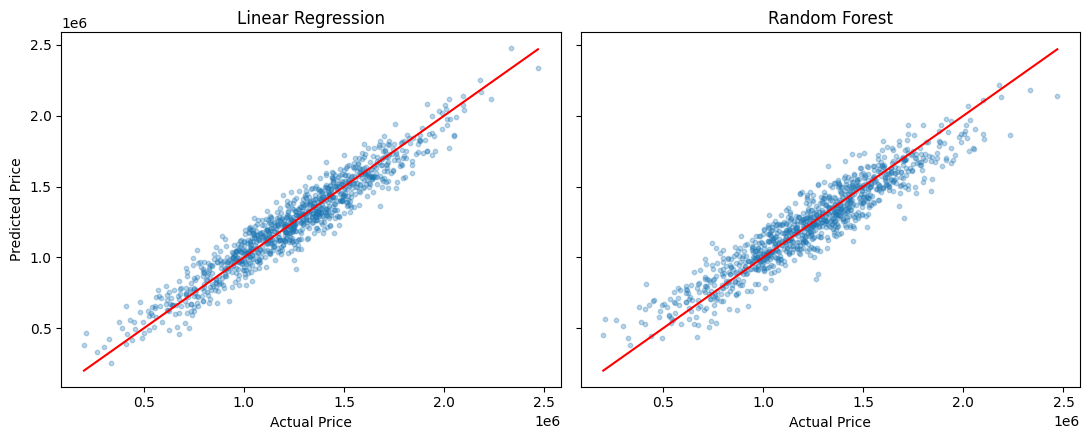

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True, sharey=True)
for ax, pred, name in zip(axes, [lin_pred, rf_pred], ["Linear Regression", "Random Forest"]):
    ax.scatter(y_test, pred, alpha=0.3, s=10)
    lims = [y_test.min(), y_test.max()]
    ax.plot(lims, lims, color="red")
    ax.set_title(name)
    ax.set_xlabel("Actual Price")
axes[0].set_ylabel("Predicted Price")
plt.tight_layout()
plt.show()

## 7. Comparison and Discussion

| Model | MAE | RMSE | R² |
|---|---|---|---|
| Linear Regression | about 80,879 | about 100,444 | 0.918 |
| Random Forest | about 94,672 | about 120,271 | 0.882 |

**Linear Regression** performed better on all three measures. It explained 91.8% of price changes and had an average error of about 80,900, which is 6.6% of the average price (1,232,000). Random Forest performed slightly worse, with an average error of 94,700 and an R² of 0.882.

**Why?** The relationship between the features and price appears mostly linear, so Linear Regression worked better than the more complex Random Forest model.

**Limitations:**
- I used only one train/test split.
- The dataset is not real Kenyan housing data.
- I used the default settings for both models.

Next steps: Test with different data splits, improve the Random Forest settings, and use real affordable housing data when available.